# Actor HMRW Experiments

Resumable HMRW experiments on `data/HyperUFG_datasets/actor`.
Each sweep saves to CSV after each parameter value so runs can resume.


In [16]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

from hypergraphx import Hypergraph
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.utils import hmrw_embeddings


In [18]:
def evaluate_embeddings(X, y, seed=42):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=3000, class_weight="balanced")
    scores = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring={"micro_f1": "f1_micro", "macro_f1": "f1_macro"},
        n_jobs=-1,
        return_train_score=False,
    )
    return float(np.mean(scores["test_micro_f1"])), float(np.mean(scores["test_macro_f1"]))


In [19]:
data_dir = Path("data") / "HyperUFG_datasets" / "actor"

with open(data_dir / "hypergraph.pickle", "rb") as f:
    hg_obj = pickle.load(f)
with open(data_dir / "labels.pickle", "rb") as f:
    labels_obj = pickle.load(f)

if isinstance(hg_obj, dict):
    edge_list = [tuple(v) for v in hg_obj.values()]
else:
    edge_list = [tuple(e) for e in hg_obj]

H = Hypergraph(edge_list)
labels_all = np.asarray(labels_obj, dtype=int).reshape(-1)

node_ids = sorted(H.get_nodes())
node_ids_int = np.asarray(node_ids, dtype=int)
y = labels_all[node_ids_int]

print(f"nodes_in_hyperedges={len(node_ids)}, hyperedges={len(edge_list)}, labels_all={len(labels_all)}, y_used={len(y)}")

if len(labels_all) != len(node_ids):
    print(
        "WARNING: labels were filtered to nodes present in the hypergraph "
        f"({len(labels_all)} -> {len(y)})."
    )


nodes_in_hyperedges=15761, hyperedges=10164, labels_all=16255, y_used=15761


In [4]:
results_dir = Path("results") / "actor"
results_dir.mkdir(parents=True, exist_ok=True)

base_params = dict(
    p=1.0,
    q=1.0,
    r=1.0,
    num_walks=5,
    walk_length=40,
    window=10,
    dim=128,
    workers=1,
)

n_repeats = 3
base_seed = 42


## Sweep q (resumable)

In [21]:
q_values = [0.25, 0.5, 1.0, 2.0, 4.0]
q_csv = results_dir / "hmrw_q_sweep.csv"

if q_csv.exists():
    results_q = pd.read_csv(q_csv)
else:
    results_q = pd.DataFrame(columns=["q", "micro_f1_mean", "micro_f1_std", "macro_f1_mean", "macro_f1_std", "n_repeats"])

done_q = set(results_q["q"].tolist()) if "q" in results_q.columns else set()

for q_val in q_values:
    if q_val in done_q:
        print(f"skip q={q_val}")
        continue

    print(f"run q={q_val}")
    micro_runs, macro_runs = [], []
    for rep in range(n_repeats):
        print(f"repeat rep={rep+1}")
        seed = base_seed + rep
        params = dict(base_params)
        params["q"] = q_val
        X = hmrw_embeddings(H, seed=seed, **params)
        micro, macro = evaluate_embeddings(X, y, seed=seed)
        micro_runs.append(micro)
        macro_runs.append(macro)

    row = {
        "q": q_val,
        "micro_f1_mean": float(np.mean(micro_runs)),
        "micro_f1_std": float(np.std(micro_runs)),
        "macro_f1_mean": float(np.mean(macro_runs)),
        "macro_f1_std": float(np.std(macro_runs)),
        "n_repeats": n_repeats,
    }
    results_q = pd.concat([results_q, pd.DataFrame([row])], ignore_index=True)
    results_q.to_csv(q_csv, index=False)

results_q = pd.read_csv(q_csv).sort_values("q")
results_q


run q=0.25
repeat rep=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_98692/386736110.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_q = pd.concat([results_q, pd.DataFrame([row])], ignore_index=True)


... (21 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,q,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std,n_repeats
0,0.25,0.420997,0.002594,0.366305,0.004052,3
1,0.50,0.419919,0.001342,0.366028,0.001344,3
2,1.00,0.416112,0.002216,0.362311,0.001204,3
3,2.00,0.419326,0.005564,0.366093,0.003178,3
4,4.00,0.421018,0.001548,0.366418,0.000410,3


## Sweep p (resumable)

In [22]:
p_values = [0.25, 0.5, 1.0, 2.0, 4.0]
p_csv = results_dir / "hmrw_p_sweep.csv"

if p_csv.exists():
    results_p = pd.read_csv(p_csv)
else:
    results_p = pd.DataFrame(columns=["p", "micro_f1_mean", "micro_f1_std", "macro_f1_mean", "macro_f1_std", "n_repeats"])

done_p = set(results_p["p"].tolist()) if "p" in results_p.columns else set()

for p_val in p_values:
    if p_val in done_p:
        print(f"skip p={p_val}")
        continue

    print(f"run p={p_val}")
    micro_runs, macro_runs = [], []
    for rep in range(n_repeats):
        print(f"repeat rep={rep+1}")
        seed = base_seed + rep
        params = dict(base_params)
        params["p"] = p_val
        X = hmrw_embeddings(H, seed=seed, **params)
        micro, macro = evaluate_embeddings(X, y, seed=seed)
        micro_runs.append(micro)
        macro_runs.append(macro)

    row = {
        "p": p_val,
        "micro_f1_mean": float(np.mean(micro_runs)),
        "micro_f1_std": float(np.std(micro_runs)),
        "macro_f1_mean": float(np.mean(macro_runs)),
        "macro_f1_std": float(np.std(macro_runs)),
        "n_repeats": n_repeats,
    }
    results_p = pd.concat([results_p, pd.DataFrame([row])], ignore_index=True)
    results_p.to_csv(p_csv, index=False)

results_p = pd.read_csv(p_csv).sort_values("p")
results_p


run p=0.25
repeat rep=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_98692/1321069246.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_p = pd.concat([results_p, pd.DataFrame([row])], ignore_index=True)


... (21 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,p,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std,n_repeats
0,0.25,0.421335,0.002408,0.365656,0.003013,3
1,0.50,0.420088,0.002595,0.363994,0.003263,3
2,1.00,0.416112,0.002216,0.362311,0.001204,3
3,2.00,0.416154,0.001773,0.363216,0.002311,3
4,4.00,0.416260,0.000855,0.362361,0.002153,3


## Sweep r (resumable)

In [23]:
r_values = [0.25, 0.5, 1.0, 2.0, 4.0]
r_csv = results_dir / "hmrw_r_sweep.csv"

if r_csv.exists():
    results_r = pd.read_csv(r_csv)
else:
    results_r = pd.DataFrame(columns=["r", "micro_f1_mean", "micro_f1_std", "macro_f1_mean", "macro_f1_std", "n_repeats"])

done_r = set(results_r["r"].tolist()) if "r" in results_r.columns else set()

for r_val in r_values:
    if r_val in done_r:
        print(f"skip r={r_val}")
        continue

    print(f"run r={r_val}")
    micro_runs, macro_runs = [], []
    for rep in range(n_repeats):
        print(f"repeat rep={rep+1}")
        seed = base_seed + rep
        params = dict(base_params)
        params["r"] = r_val
        X = hmrw_embeddings(H, seed=seed, **params)
        micro, macro = evaluate_embeddings(X, y, seed=seed)
        micro_runs.append(micro)
        macro_runs.append(macro)

    row = {
        "r": r_val,
        "micro_f1_mean": float(np.mean(micro_runs)),
        "micro_f1_std": float(np.std(micro_runs)),
        "macro_f1_mean": float(np.mean(macro_runs)),
        "macro_f1_std": float(np.std(macro_runs)),
        "n_repeats": n_repeats,
    }
    results_r = pd.concat([results_r, pd.DataFrame([row])], ignore_index=True)
    results_r.to_csv(r_csv, index=False)

results_r = pd.read_csv(r_csv).sort_values("r")
results_r


run r=0.25
repeat rep=1


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_98692/1758124763.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_r = pd.concat([results_r, pd.DataFrame([row])], ignore_index=True)


... (21 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


repeat rep=3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,r,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std,n_repeats
0,0.25,0.414082,0.002048,0.359769,0.001929,3
1,0.50,0.420363,0.002828,0.364893,0.002159,3
2,1.00,0.416112,0.002216,0.362311,0.001204,3
3,2.00,0.419707,0.002361,0.364833,0.002258,3
4,4.00,0.415202,0.004133,0.364471,0.001927,3


## Plot q, p, r

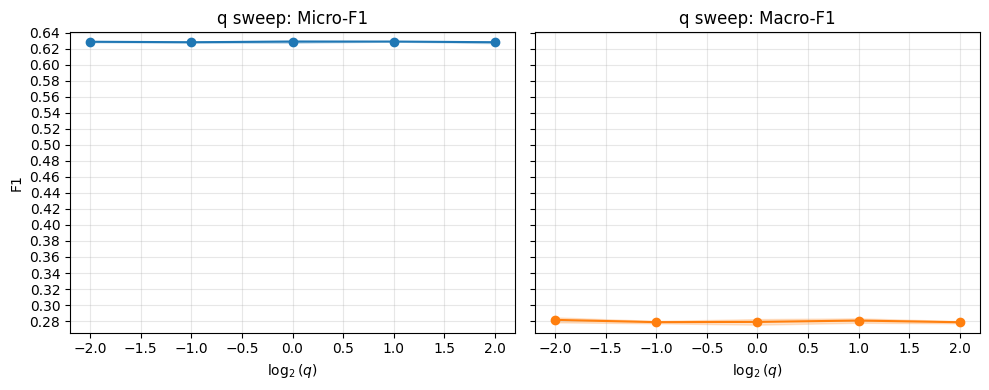

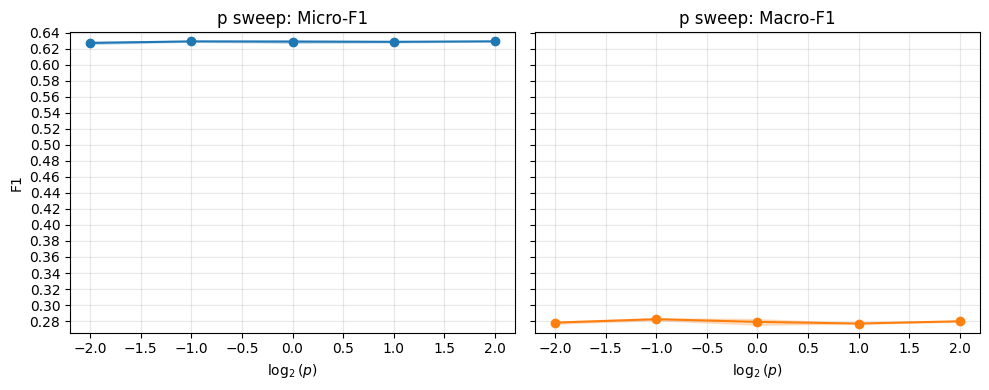

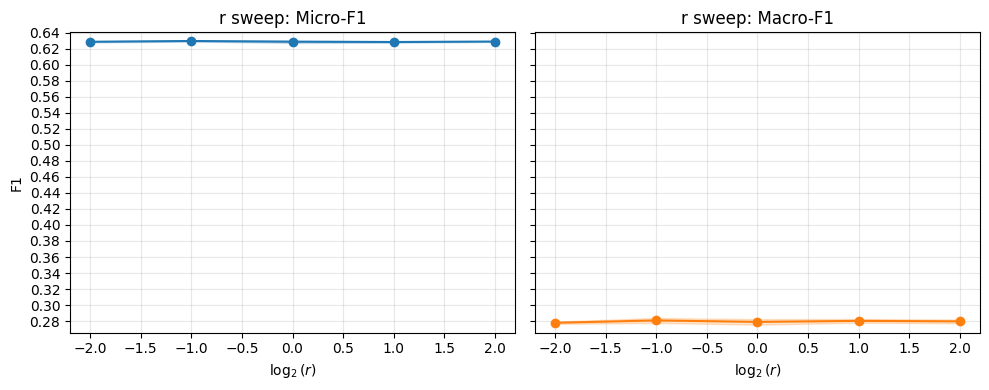

In [8]:
qdf = pd.read_csv(results_dir / "hmrw_q_sweep.csv").sort_values("q")
pdf = pd.read_csv(results_dir / "hmrw_p_sweep.csv").sort_values("p")
rdf = pd.read_csv(results_dir / "hmrw_r_sweep.csv").sort_values("r")

for df, param, name in [(qdf, "q", "q"), (pdf, "p", "p"), (rdf, "r", "r")]:
    x = np.log2(df[param].to_numpy())
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    axes[0].plot(x, df["micro_f1_mean"], marker="o", color="tab:blue")
    axes[0].fill_between(x, df["micro_f1_mean"] - df["micro_f1_std"], df["micro_f1_mean"] + df["micro_f1_std"], alpha=0.2, color="tab:blue")
    axes[0].set_title(f"{name} sweep: Micro-F1")
    axes[0].set_xlabel(rf"$\log_2({param})$")
    axes[0].set_ylabel("F1")

    axes[1].plot(x, df["macro_f1_mean"], marker="o", color="tab:orange")
    axes[1].fill_between(x, df["macro_f1_mean"] - df["macro_f1_std"], df["macro_f1_mean"] + df["macro_f1_std"], alpha=0.2, color="tab:orange")
    axes[1].set_title(f"{name} sweep: Macro-F1")
    axes[1].set_xlabel(rf"$\log_2({param})$")

    ymin = min((df["micro_f1_mean"] - df["micro_f1_std"]).min(), (df["macro_f1_mean"] - df["macro_f1_std"]).min())
    ymax = max((df["micro_f1_mean"] + df["micro_f1_std"]).max(), (df["macro_f1_mean"] + df["macro_f1_std"]).max())

    for ax in axes:
        ax.set_ylim(max(0.0, ymin - 0.01), min(1.0, ymax + 0.01))
        ax.grid(True, alpha=0.3)
        ax.yaxis.set_major_locator(MultipleLocator(0.02))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

    fig.tight_layout()
    plt.show()
